# 05 · ¿La señal de expresión sobre el CPS es independiente del número de células?

En el notebook 04 la expresión predijo el CPS (Spearman 0,58 en la fusión) mejor que el control técnico (0,48).
Pero el CPS también se correlaciona con el número de células del donante (−0,62), así que hay que descartar que la
expresión esté "leyendo" el número de células. Dos pruebas:

1. **Correlación parcial.** Correlación entre el CPS predicho por la expresión y el CPS real **descontando** las 12
   variables técnicas del donante (log de células y de recuentos de los 6 tipos).
2. **Modelo de residuos** (la más exigente). En cada pliegue, con los donantes de entrenamiento:
   un modelo técnico predice el CPS → nos quedamos con lo que **no** explica (el residuo) → la expresión intenta
   predecir ese residuo. En test se compara con el residuo real. Si la correlación supera claramente a la de las
   permutaciones, la expresión contiene información sobre la progresión que las variables técnicas no tienen.

**Ejecución** (~5–10 min): `jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=3600 notebooks\05_independencia.ipynb`

In [1]:
import json
import sys
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))
from tfm import baselines as B
from tfm import evaluation as E
from tfm.config import load_config

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

cfg = load_config(ROOT)
COL, PB, EV, BL = cfg["columns"], cfg["pseudobulk"], cfg["evaluation"], cfg["baselines"]
SEED = cfg["seed"]
TABLAS, FIGS = cfg["paths"]["tables"], cfg["paths"]["figures"]
CPS = "Continuous Pseudo-progression Score"

def guardar(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", encoding="utf-8"); return df

def guardar_fig(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png", dpi=150, bbox_inches="tight")

pb = ad.read_h5ad(ROOT / PB["file"])
pb_ig = ad.read_h5ad(ROOT / PB["file_igualado"])
datos, y = B.build_type_data(pb_ig, pb, cfg)
cps = pb.obs.groupby(pb.obs[COL["donor"]].astype(str), observed=True)[CPS].first().astype(float).reindex(y.index)
ok = cps.notna()
datos = {t: (c.loc[c.index.isin(cps.index[ok])], tec.loc[tec.index.isin(cps.index[ok])]) for t, (c, tec) in datos.items()}
cps, y = cps[ok], y[ok]

# 12 variables técnicas del donante: log10 de n_celulas y de recuentos originales en cada uno de los 6 tipos
tec, _ = E.technical_features(pb, cfg)
tec = tec.reindex(cps.index).fillna(0)
print(f"{len(cps)} donantes | variables técnicas: {tec.shape[1]}")

def ridge_expr(n_tech):
    return make_pipeline(B.LogCPMTopVar(BL["n_genes"], PB["min_cpm"], PB["min_frac"], n_tech), StandardScaler(),
                         RidgeCV(alphas=np.logspace(0, 5, 11)))

def ridge_tec():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 11)))

splits = E.donor_splits(y.values, n_splits=EV["n_splits"], n_repeats=EV["n_repeats_baselines"], seed=SEED)

74 donantes | variables técnicas: 12


## 1. Correlación parcial

Repetimos la regresión del CPS del notebook 04 (mismas particiones) y, para cada tipo y para la fusión, calculamos
la correlación de Spearman entre la predicción media (10 repeticiones) y el CPS real, **sin control** y
**controlando** por las 12 variables técnicas.

**Cuidado con el signo.** Sin señal, la validación cruzada produce correlaciones algo **negativas** (lo vimos en las
permutaciones del notebook 04), y el p-valor clásico las marcaría como "significativas". Por eso usamos un contraste
de **una cola**: solo una correlación parcial positiva cuenta como evidencia. Como el sesgo empuja hacia valores
negativos, el contraste es conservador.

In [2]:
_, pred = B.run_regression(datos, cps, splits, {"ridge (expresión)": (ridge_expr, "expresion")})
_, Yf = B.fuse_regression(pred, cps, "ridge (expresión)")
filas = []
for t, Y in list({t: pred[("ridge (expresión)", t)] for t in datos}.items()) + [("fusión", Yf)]:
    media = np.nanmean(Y, axis=0)
    m = ~np.isnan(media)
    rho = pd.Series(media[m]).corr(pd.Series(cps.values[m]), method="spearman")
    rho_p, p = E.partial_spearman(media[m], cps.values[m], tec.values[m])
    p_una_cola = p / 2 if rho_p > 0 else 1 - p / 2           # solo una correlación POSITIVA es evidencia
    filas.append({"tipo": t, "n": int(m.sum()), "spearman": rho, "spearman_parcial": rho_p,
                  "p_parcial_una_cola": p_una_cola})
parcial = guardar(pd.DataFrame(filas).set_index("tipo"), "independencia_correlacion_parcial")
display(parcial.round(3))

  AST        ridge (expresión)                 6 s


  L2IT-GLU   ridge (expresión)                12 s


  MGC        ridge (expresión)                17 s


  OLG        ridge (expresión)                23 s


  SST-GABA   ridge (expresión)                28 s


  VIP-GABA   ridge (expresión)                34 s


,n,spearman,spearman_parcial,p_parcial_una_cola
tipo,,,,
AST,64,0.565,0.441,0.001
L2IT-GLU,63,0.473,0.317,0.012
MGC,63,0.524,0.333,0.008
OLG,60,0.510,0.473,0.000
SST-GABA,63,0.467,0.312,0.013
VIP-GABA,66,0.484,0.228,0.049
fusión,74,0.582,0.366,0.002


## 2. Modelo de residuos

Tres columnas por tipo:

- `spearman_tecnico`: el modelo técnico solo (12 variables) prediciendo el CPS.
- `spearman_tecnico_mas_expresion`: predicción técnica + residuo predicho por la expresión.
- `spearman_residuo`: lo que importa: ¿predice la expresión la parte del CPS que el modelo técnico no explica?

In [3]:
met_res, pred_res, real, pred_tec = B.run_residual_regression(datos, cps, tec, splits, ridge_expr, ridge_tec)
fus_res, R = B.fuse_residual(pred_res, cps, real, pred_tec)
todo = pd.concat([met_res, fus_res])
cols = ["spearman_tecnico", "spearman_tecnico_mas_expresion", "spearman_residuo"]
tabla_res = guardar(B.summarize_by(todo, keys=("tipo",), metricas=cols), "independencia_residuos")
display(tabla_res.round(3))

  AST             6 s


  L2IT-GLU       13 s


  MGC            19 s


  OLG            25 s


  SST-GABA       31 s


  VIP-GABA       37 s


,spearman_tecnico_media,spearman_tecnico_sd,spearman_tecnico_mas_expresion_media,spearman_tecnico_mas_expresion_sd,spearman_residuo_media,spearman_residuo_sd,n_donantes
tipo,,,,,,,
AST,0.477,0.055,0.593,0.053,0.295,0.046,64
L2IT-GLU,0.375,0.052,0.493,0.050,0.370,0.052,63
MGC,0.426,0.044,0.569,0.048,0.392,0.048,63
OLG,0.438,0.035,0.593,0.041,0.458,0.047,60
SST-GABA,0.379,0.049,0.547,0.046,0.450,0.038,63
VIP-GABA,0.415,0.050,0.554,0.044,0.379,0.058,66
fusión,0.505,0.050,0.621,0.049,0.356,0.030,74


### Permutación para el residuo

Barajamos el CPS entre donantes y repetimos todo el proceso (modelo técnico + expresión sobre el residuo) 20 veces.

In [4]:
N_PERM = 20
rng = np.random.default_rng(SEED)
nulo = {t: [] for t in list(datos) + ["fusión"]}
for i in range(N_PERM):
    cp = pd.Series(rng.permutation(cps.values), index=cps.index)
    sp_ = E.donor_splits(y.values, n_splits=EV["n_splits"], n_repeats=1, seed=SEED + i)
    m_, pr_, re_, pt_ = B.run_residual_regression(datos, cp, tec, sp_, ridge_expr, ridge_tec, verbose=False)
    f_, _ = B.fuse_residual(pr_, cp, re_, pt_)
    for _, fila in pd.concat([m_, f_]).iterrows():
        nulo[fila["tipo"]].append(fila["spearman_residuo"])
    print(f"\r  permutación {i + 1}/{N_PERM}", end="")
print()

obs = tabla_res["spearman_residuo_media"]
perm = pd.DataFrame({t: {"observado": obs[t], "nulo_media": np.mean(v), "nulo_p95": np.percentile(v, 95),
                         "p_empirico": (1 + np.sum(np.array(v) >= obs[t])) / (1 + len(v))}
                     for t, v in nulo.items()}).T
guardar(perm, "independencia_residuos_permutacion")
display(perm.round(3))

  permutación 1/20

  permutación 2/20

  permutación 3/20

  permutación 4/20

  permutación 5/20

  permutación 6/20

... (11 outputs left out)

  permutación 18/20

  permutación 19/20

  permutación 20/20


,observado,nulo_media,nulo_p95,p_empirico
AST,0.295,-0.116,0.069,0.048
L2IT-GLU,0.370,-0.074,0.128,0.048
MGC,0.392,-0.066,0.132,0.048
OLG,0.458,-0.088,0.094,0.048
SST-GABA,0.450,-0.048,0.243,0.048
VIP-GABA,0.379,-0.045,0.151,0.048
fusión,0.356,-0.049,0.186,0.048


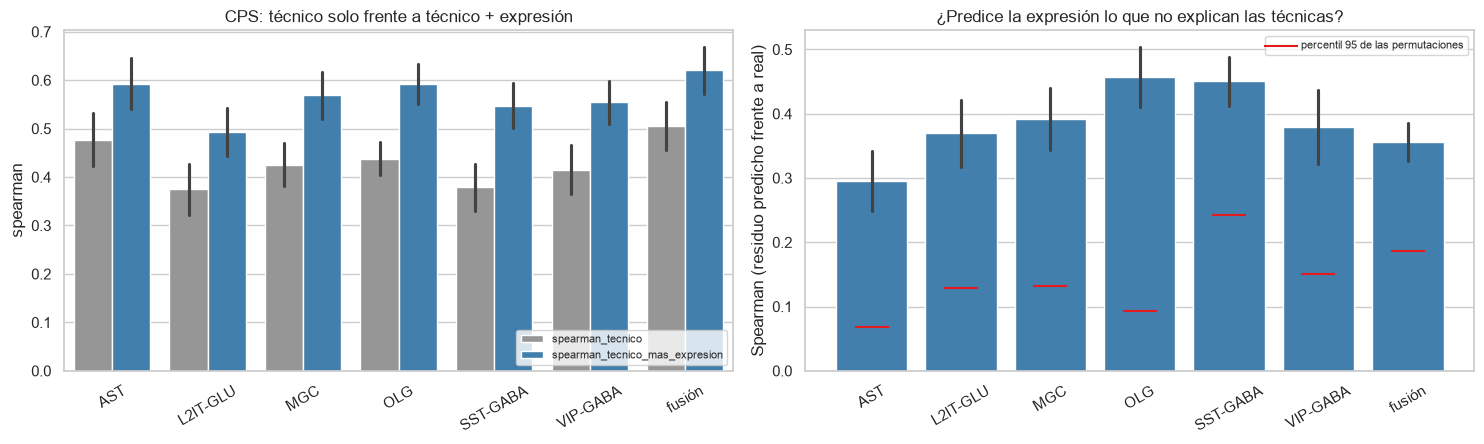

In [5]:
orden = sorted(datos) + ["fusión"]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6))
d = todo.melt(id_vars=["tipo", "repeticion"], value_vars=cols[:2], var_name="modelo", value_name="spearman")
sns.barplot(data=d, x="tipo", y="spearman", hue="modelo", order=orden, errorbar="sd", ax=axs[0],
            palette=["#969696", "#3182bd"])
axs[0].set_title("CPS: técnico solo frente a técnico + expresión"); axs[0].set_xlabel("")
axs[0].tick_params(axis="x", rotation=30); axs[0].legend(fontsize=8, loc="lower right")
sns.barplot(data=todo, x="tipo", y="spearman_residuo", order=orden, errorbar="sd", ax=axs[1], color="#3182bd")
axs[1].scatter(range(len(orden)), [perm.loc[t, "nulo_p95"] for t in orden], marker="_", s=600, color="#e41a1c",
               zorder=3, label="percentil 95 de las permutaciones")
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_title("¿Predice la expresión lo que no explican las técnicas?"); axs[1].set_xlabel("")
axs[1].set_ylabel("Spearman (residuo predicho frente a real)"); axs[1].tick_params(axis="x", rotation=30)
axs[1].legend(fontsize=8)
fig.tight_layout(); guardar_fig(fig, "independencia"); plt.show()

In [6]:
resumen = {
    "correlacion_parcial": parcial[["spearman", "spearman_parcial", "p_parcial_una_cola"]].round(4).to_dict(orient="index"),
    "residuos": tabla_res[[c + "_media" for c in cols]].round(3).to_dict(orient="index"),
    "permutacion_residuo": perm.round(3).to_dict(orient="index"),
}
(TABLAS / "independencia_resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(resumen, indent=2, ensure_ascii=False))

{
  "correlacion_parcial": {
    "AST": {
      "spearman": 0.5651,
      "spearman_parcial": 0.4414,
      "p_parcial_una_cola": 0.0005
    },
    "L2IT-GLU": {
      "spearman": 0.4731,
      "spearman_parcial": 0.3168,
      "p_parcial_una_cola": 0.0118
    },
    "MGC": {
      "spearman": 0.5242,
      "spearman_parcial": 0.333,
      "p_parcial_una_cola": 0.0085
    },
    "OLG": {
      "spearman": 0.5103,
      "spearman_parcial": 0.4731,
      "p_parcial_una_cola": 0.0003
    },
    "SST-GABA": {
      "spearman": 0.4672,
      "spearman_parcial": 0.3123,
      "p_parcial_una_cola": 0.0128
    },
    "VIP-GABA": {
      "spearman": 0.4837,
      "spearman_parcial": 0.2275,
      "p_parcial_una_cola": 0.049
    },
    "fusión": {
      "spearman": 0.5823,
      "spearman_parcial": 0.3663,
      "p_parcial_una_cola": 0.0017
    }
  },
  "residuos": {
    "AST": {
      "spearman_tecnico_media": 0.477,
      "spearman_tecnico_mas_expresion_media": 0.593,
      "spearman_residuo_m